### Step 1: Introduction to the Dataset

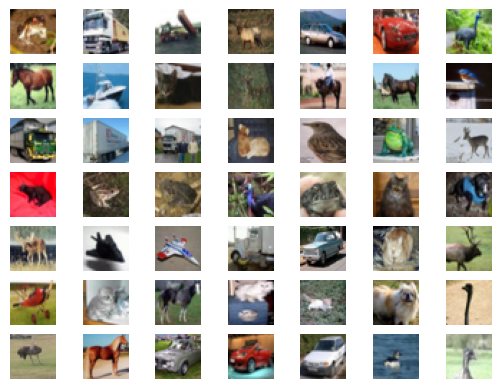

In [60]:
# example of loading and plotting the cifar10 dataset
from keras.datasets.cifar10 import load_data
from matplotlib import pyplot
# load the images into memory
(trainX, trainy), (testX, testy) = load_data()
# plot images from the training dataset
for i in range(49):
	# define subplot
	pyplot.subplot(7, 7, 1 + i)
	# turn off axis
	pyplot.axis('off')
	# plot raw pixel data
	pyplot.imshow(trainX[i])
pyplot.show()

In [61]:
print(trainX.shape)

(50000, 32, 32, 3)


### Step 2: Defining the Discriminator Model



In [62]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, LeakyReLU
from tensorflow.keras.utils import plot_model
import numpy as np

In [63]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, LeakyReLU
from tensorflow.keras.utils import plot_model

# Define the discriminator model
def define_discriminator(in_shape=(32,32,3)):
    model = Sequential()

    # First convolutional block
    model.add(Conv2D(64, (3,3), padding='same', input_shape=in_shape))
    model.add(LeakyReLU(alpha=0.2))

    # Second convolutional block (downsample)
    model.add(Conv2D(128, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(alpha=0.2))

    # Third convolutional block (downsample)
    model.add(Conv2D(128, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(alpha=0.2))

    # Fourth convolutional block (downsample)
    model.add(Conv2D(256, (3,3), strides=(2,2), padding='same'))
    model.add(LeakyReLU(alpha=0.2))

    # Classifier block
    model.add(Flatten())
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))

    # Compile the model using the correct parameter: learning_rate
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])

    return model


Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_44 (Conv2D)              │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_68 (LeakyReLU)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_69 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_70 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_71 (LeakyReLU)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 522,497 (1.99 MB)

 Trainable params: 522,497 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

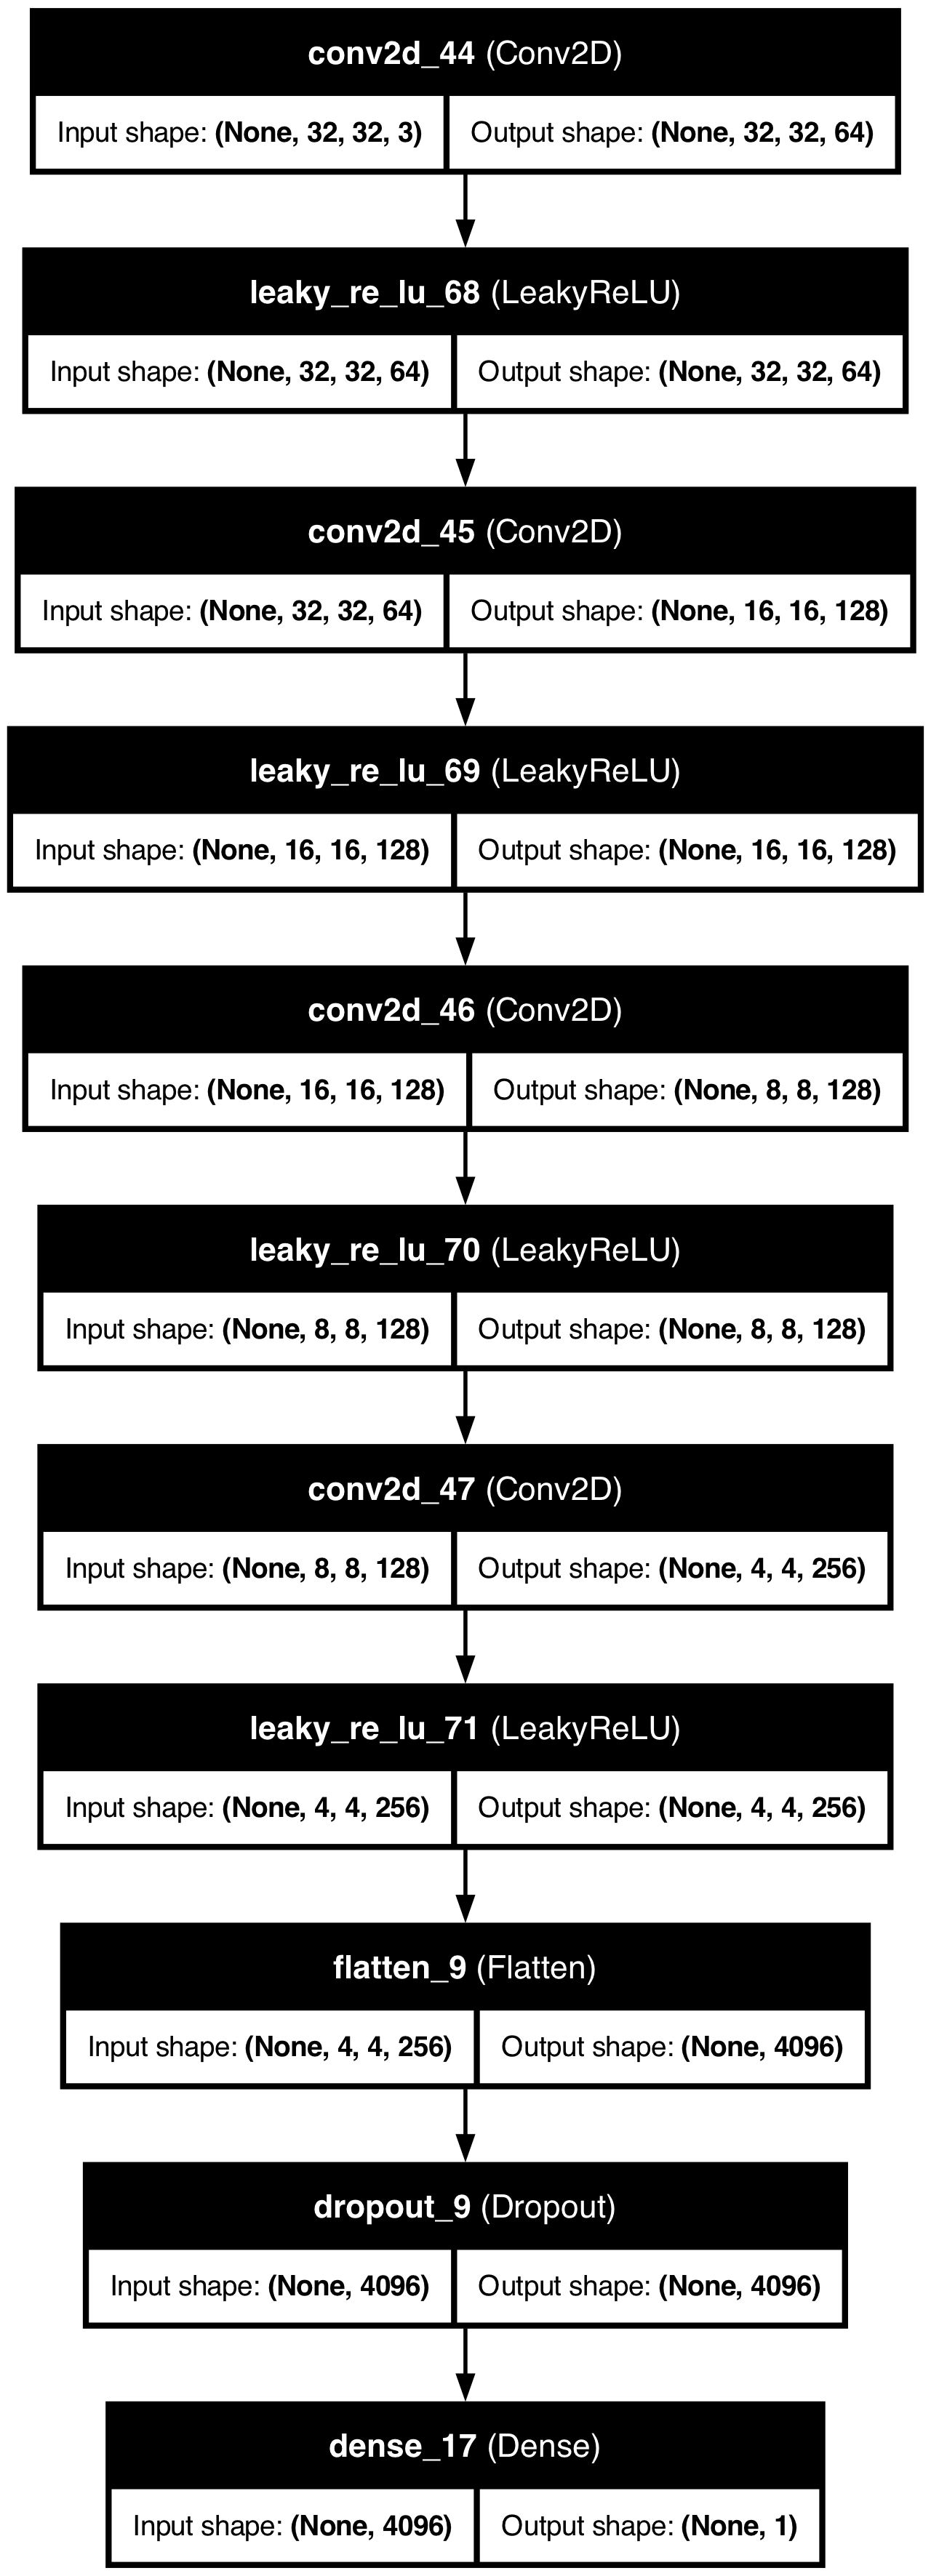

In [64]:
# Create the discriminator
model = define_discriminator()

# Display model summary
model.summary()

# Visualize and save the model architecture
plot_model(model, to_file='discriminator_plot.png', show_shapes=True, show_layer_names=True)

In [65]:
# load and prepare cifar10 training images
def load_real_samples():
	# load cifar10 dataset
	(trainX, _), (_, _) = load_data()
	# convert from unsigned ints to floats
	X = trainX.astype('float32')
	# scale from [0,255] to [-1,1]
	X = (X - 127.5) / 127.5
	return X

In [66]:
Xcheck = load_real_samples()
print(Xcheck.shape)

(50000, 32, 32, 3)


In [67]:
from numpy.random import randint
from numpy import ones

# select real samples (we select 64 real images from the dataset)
def generate_real_samples(dataset, n_samples):
    # choose random instances
    ix = randint(0, dataset.shape[0], n_samples)
    # retrieve selected images
    X = dataset[ix]
    # generate 'real' class labels (1)
    y = ones((n_samples, 1))
    return X, y


In [68]:
Xcheck,ycheck = generate_real_samples(Xcheck, 64)
print(Xcheck.shape)
print(ycheck.shape)

(64, 32, 32, 3)
(64, 1)


### Step 3: Generate random fake data (no generator)

In [69]:
from numpy.random import rand
from numpy import zeros

# generate n fake samples with class labels
def generate_fake_samples(n_samples):
    # generate uniform random numbers in [0,1]
    X = rand(32 * 32 * 3 * n_samples)
    # update to have the range [-1, 1]
    X = -1 + X * 2
    # reshape into a batch of color images
    X = X.reshape((n_samples, 32, 32, 3))
    # generate 'fake' class labels (0)
    y = zeros((n_samples, 1))
    return X, y


In [70]:
Xcheck,ycheck = generate_fake_samples(64)
print(Xcheck.shape)
print(ycheck.shape)

(64, 32, 32, 3)
(64, 1)


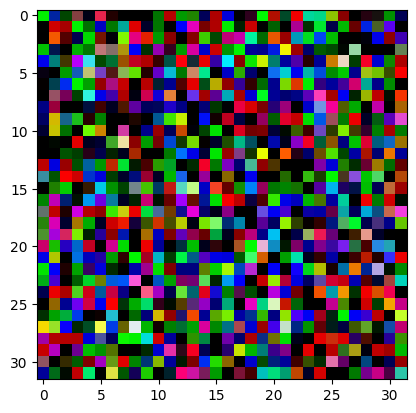

In [71]:
pyplot.imshow(Xcheck[10])

### Step 4: Show training of discriminator model on random fake data

In [72]:
# train the discriminator model
def train_discriminator(model, dataset, n_iter=100, n_batch=128):
	half_batch = int(n_batch / 2)
 #128/2 = 64
	# manually enumerate epochs
	for i in range(n_iter):
		# get randomly selected 'real' samples
		X_real, y_real = generate_real_samples(dataset, half_batch)
		# update discriminator on real samples
		_, real_acc = model.train_on_batch(X_real, y_real)
		# generate 'fake' examples
		X_fake, y_fake = generate_fake_samples(half_batch)
		# update discriminator on fake samples
		_, fake_acc = model.train_on_batch(X_fake, y_fake)
		# summarize performance
		print('>%d real=%.0f%% fake=%.0f%%' % (i+1, real_acc*100, fake_acc*100))

In [73]:
#Example Training

# define the discriminator model
model = define_discriminator()
# load image data
dataset = load_real_samples()
# fit the model
train_discriminator(model, dataset)

/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


>1 real=53% fake=27%
>2 real=51% fake=39%
>3 real=51% fake=46%
>4 real=53% fake=55%
>5 real=58% fake=62%
>6 real=65% fake=68%
>7 real=69% fake=71%
>8 real=72% fake=74%
>9 real=75% fake=76%
>10 real=77% fake=78%
>11 real=79% fake=80%
>12 real=81% fake=82%
>13 real=82% fake=83%
>14 real=84% fake=84%
>15 real=85% fake=85%
>16 real=86% fake=86%
>17 real=87% fake=87%
>18 real=87% fake=88%
>19 real=88% fake=88%
>20 real=89% fake=89%
>21 real=89% fake=89%
>22 real=90% fake=90%
>23 real=90% fake=90%
>24 real=91% fake=91%
>25 real=91% fake=91%
>26 real=91% fake=91%
>27 real=92% fake=92%
>28 real=92% fake=92%
>29 real=92% fake=92%
>30 real=92% fake=93%
>31 real=93% fake=93%
>32 real=93% fake=93%
>33 real=93% fake=93%
>34 real=93% fake=93%
>35 real=94% fake=94%
>36 real=94% fake=94%
>37 real=94% fake=94%
>38 real=94% fake=94%
>39 real=94% fake=94%
>40 real=94% fake=94%
>41 real=94% fake=95%
>42 real=95% fake=95%
>43 real=95% fake=95%
>44 real=95% fake=95%
>45 real=95% fake=95%
>46 real=95% fake=9

## Step 5: Define Generator Model

In [74]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Reshape, Conv2D, Conv2DTranspose, LeakyReLU
from tensorflow.keras.utils import plot_model


In [75]:
# define the standalone generator model
def define_generator(latent_dim):
	model = Sequential()
	# foundation for 4x4 image

  ## We first convert the 100 input nodes to 256 images of size 4*4.
  ## Why 256: Because each image can capture different features of input data.
  ## Why specifically 4*4 and 256: it's an experimental choice.

	n_nodes = 256 * 4 * 4
	model.add(Dense(n_nodes, input_dim=latent_dim))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Reshape((4, 4, 256)))

	# upsample to 8x8. Conv2D is used for upsampling.
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
	model.add(LeakyReLU(alpha=0.2))
	# upsample to 16x16
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
	model.add(LeakyReLU(alpha=0.2))
	# upsample to 32x32
	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
	model.add(LeakyReLU(alpha=0.2))
	# output layer
	model.add(Conv2D(3, (3,3), activation='tanh', padding='same'))
	return model

/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 4096)           │       413,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_76 (LeakyReLU)      │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_8 (Reshape)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_24             │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_77 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_25             │ (None, 16, 16, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_78 (LeakyReLU)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_26             │ (None, 32, 32, 128)    │       262,272 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_79 (LeakyReLU)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_52 (Conv2D)              │ (None, 32, 32, 3)      │         3,459 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,466,115 (5.59 MB)

 Trainable params: 1,466,115 (5.59 MB)

 Non-trainable params: 0 (0.00 B)

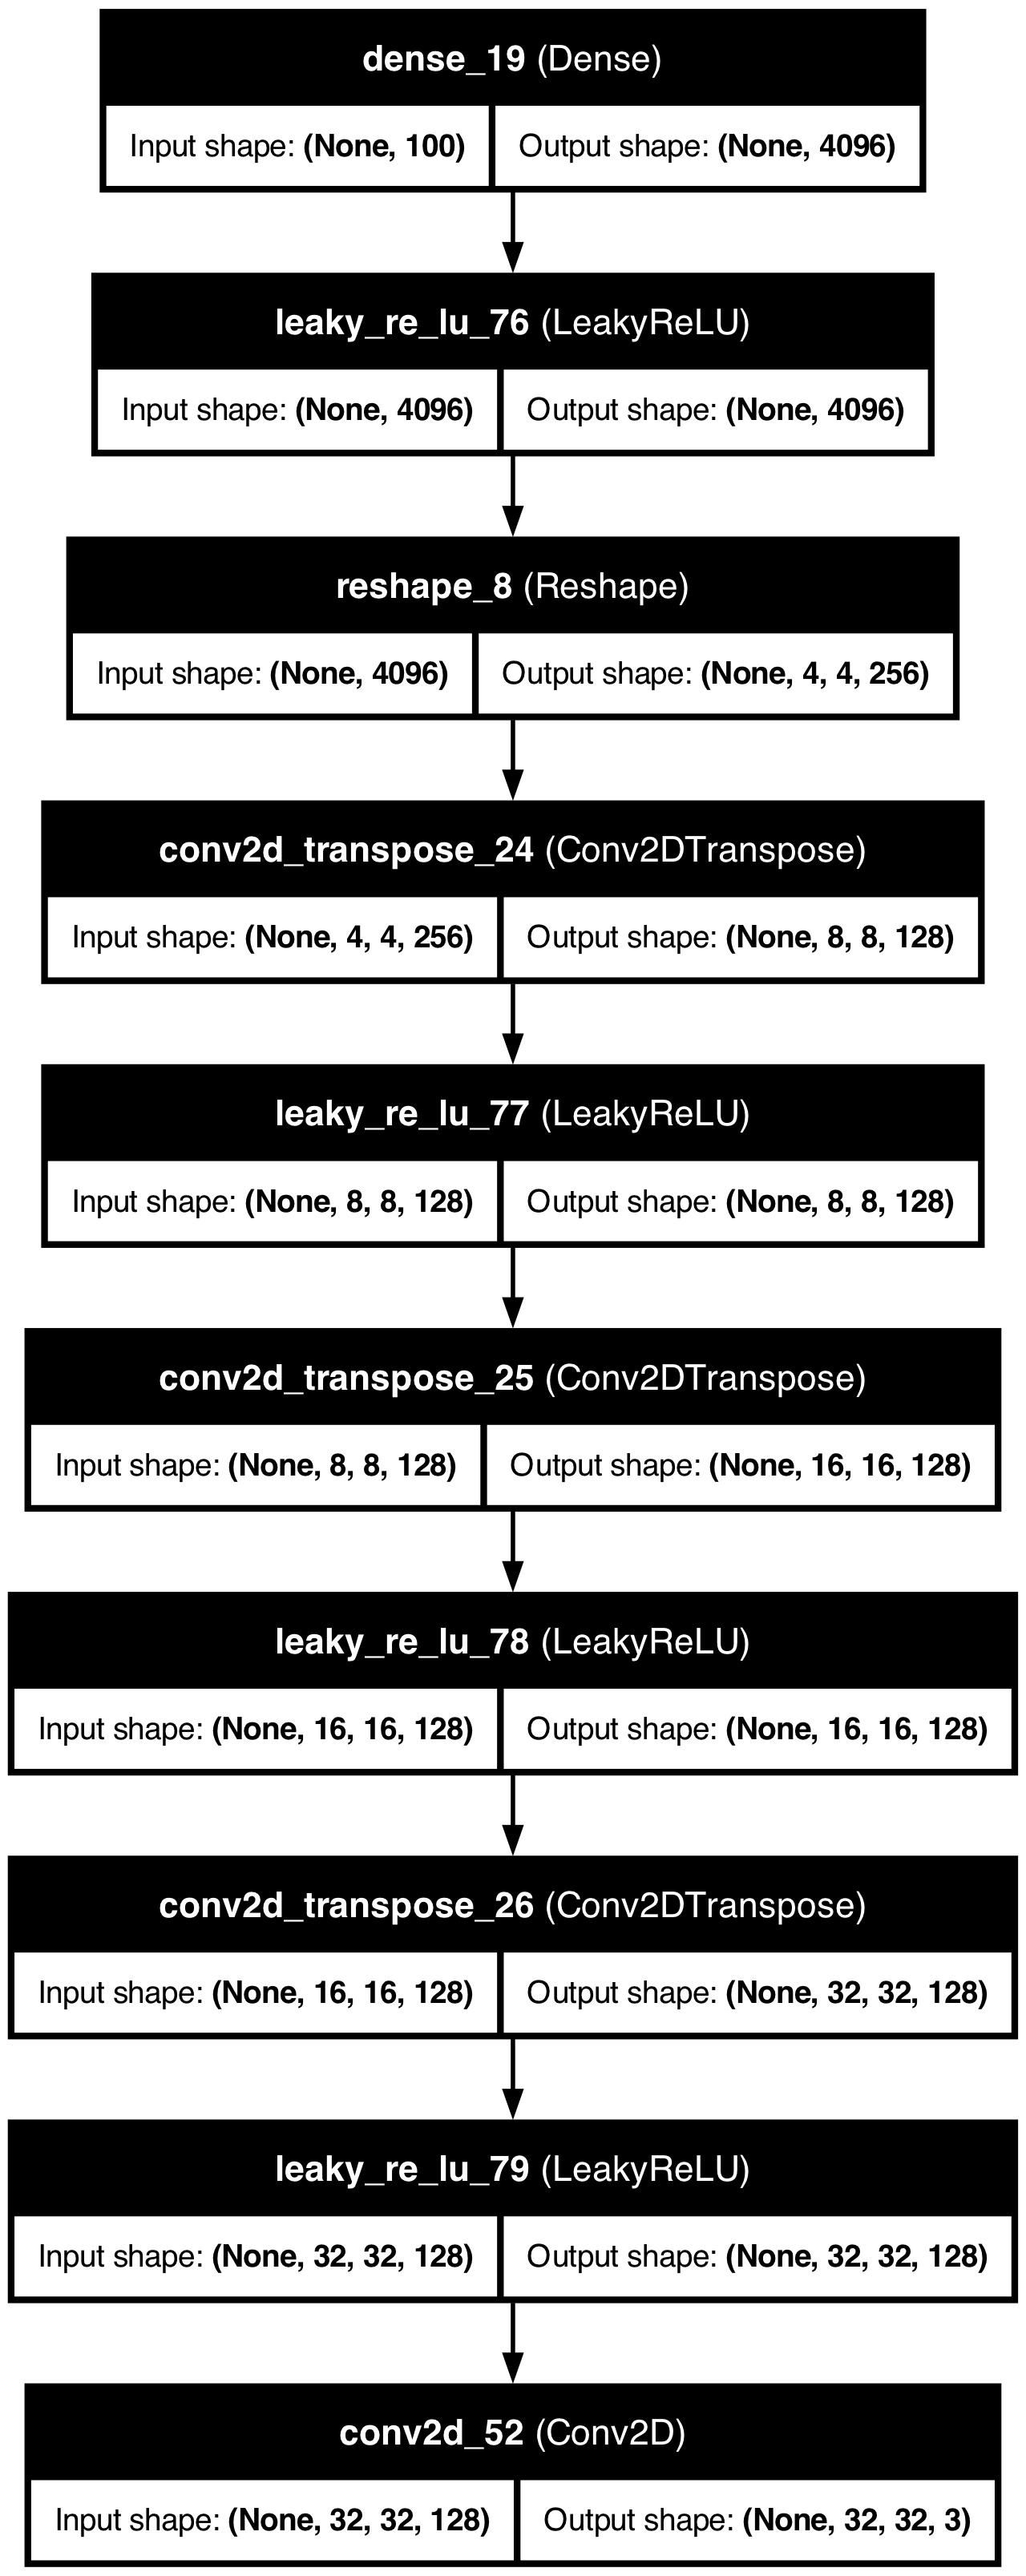

In [76]:
# define the size of the latent space
latent_dim = 100
# define the generator model
model = define_generator(latent_dim)
# summarize the model
model.summary()
# plot the model
plot_model(model, to_file='generator_plot.png', show_shapes=True, show_layer_names=True)

## Step 6: Generate multiple images from generator and feed them to the generator model

In [77]:
from numpy.random import randn

# generate points in latent space as input for the generator
# function 1
def generate_latent_points(latent_dim, n_samples):
	# generate points in the latent space
	# 64*100 = 6400 values
	x_input = randn(latent_dim * n_samples)
	# reshape into a batch of inputs for the network
	x_input = x_input.reshape(n_samples, latent_dim)
	return x_input

In [78]:
x_input = generate_latent_points(100, 64)
print(x_input.shape)

(64, 100)


In [79]:
# use the generator to generate n fake examples, with class labels
# function 2
def generate_fake_samples(g_model, latent_dim, n_samples):
	# generate points in latent space
	x_input = generate_latent_points(latent_dim, n_samples)
	# predict outputs
	X = g_model.predict(x_input)
	# create 'fake' class labels (0)
	y = zeros((n_samples, 1))
	return X, y

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


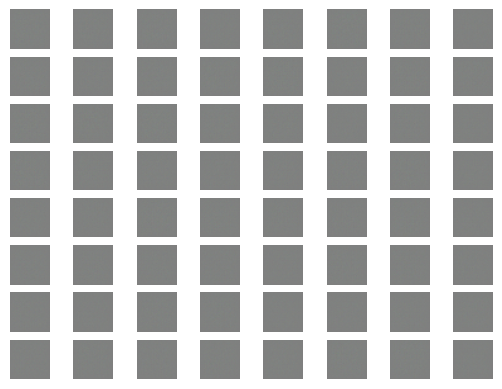

In [80]:
# size of the latent space
latent_dim = 100
# define the discriminator model
model = define_generator(latent_dim)
# generate samples
n_samples = 64
X, _ = generate_fake_samples(model, latent_dim, n_samples)
# scale pixel values from [-1,1] to [0,1]
X = (X + 1) / 2.0
# plot the generated samples
for i in range(n_samples):
	# define subplot
	pyplot.subplot(8, 8, 1 + i)
	# turn off axis labels
	pyplot.axis('off')
	# plot single image
	pyplot.imshow(X[i])
# show the figure
pyplot.show()

## Step 7: Create a model which links the generator and discriminator

In [81]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

# define the combined generator and discriminator model (GAN)
def define_gan(g_model, d_model):
    # make discriminator weights not trainable during GAN training
    d_model.trainable = False

    # create sequential GAN model
    model = Sequential()

    # add generator model
    model.add(g_model)

    # add discriminator model
    model.add(d_model)

    # compile GAN model with corrected learning_rate argument
    opt = Adam(learning_rate=0.0002, beta_1=0.5)
    model.compile(loss='binary_crossentropy', optimizer=opt)

    return model


/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_26 (Sequential)      │ (None, 32, 32, 3)      │     1,466,115 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_25 (Sequential)      │ (None, 1)              │       522,497 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,988,612 (7.59 MB)

 Trainable params: 1,466,115 (5.59 MB)

 Non-trainable params: 522,497 (1.99 MB)

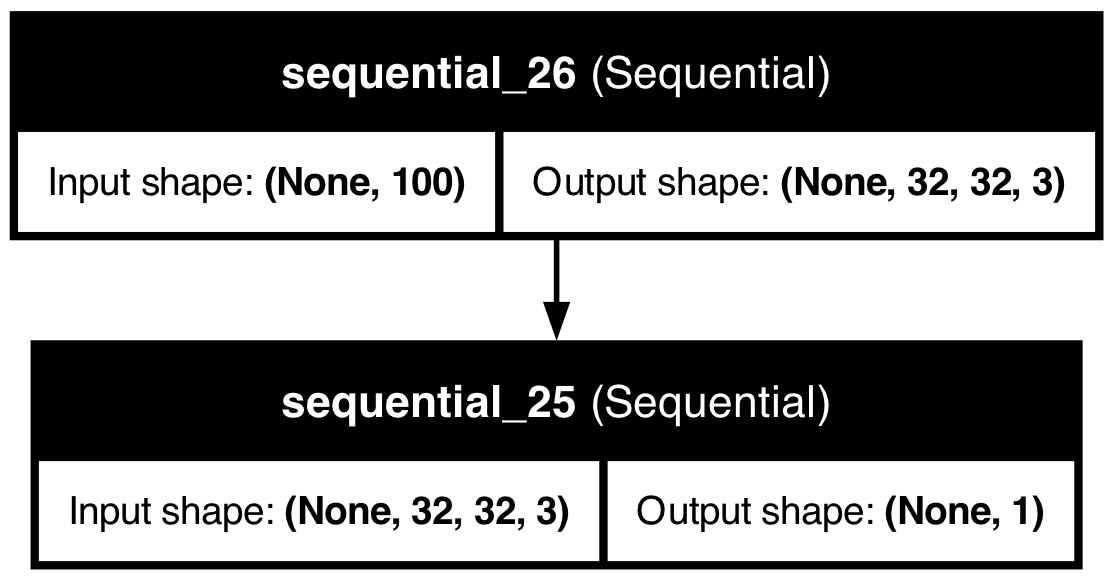

In [82]:
# size of the latent space
latent_dim = 100
# create the discriminator
d_model = define_discriminator()
# create the generator
g_model = define_generator(latent_dim)
# create the gan
gan_model = define_gan(g_model, d_model)
# summarize gan model
gan_model.summary()
# plot gan model
plot_model(gan_model, to_file='gan_plot.png', show_shapes=True, show_layer_names=True)

## Step 8: Define the full GAN training loop. This involves 3 steps:
 (a) Discriminator real image training

 (b) Discriminator fake image training

 (c) Generator training with frozen discriminator

In [83]:
# train the generator and discriminator
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=200, n_batch=128):
	bat_per_epo = int(dataset.shape[0] / n_batch)
	half_batch = int(n_batch / 2)
	# manually enumerate epochs
	for i in range(n_epochs):
		# enumerate batches over the training set
		for j in range(bat_per_epo):
			d_model.trainable = True
			# get randomly selected 'real' samples
			X_real, y_real = generate_real_samples(dataset, half_batch)
			# update discriminator model weights
			d_loss1, _ = d_model.train_on_batch(X_real, y_real)
			# generate 'fake' examples
			X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
			# update discriminator model weights
			d_loss2, _ = d_model.train_on_batch(X_fake, y_fake)
			d_model.trainable = False
			# prepare points in latent space as input for the generator
			X_gan = generate_latent_points(latent_dim, n_batch)
			# create inverted labels for the fake samples
			### Labels or the actual result which we want
			y_gan = ones((n_batch, 1))
			# update the generator via the discriminator's error
			g_loss = gan_model.train_on_batch(X_gan, y_gan)
			# summarize loss on this batch
			print('>%d, %d/%d, d1=%.3f, d2=%.3f g=%.3f' %
				(i+1, j+1, bat_per_epo, d_loss1, d_loss2, g_loss))
		# evaluate the model performance, sometimes
		if (i+1) % 1 == 0:
			summarize_performance(i, g_model, d_model, dataset, latent_dim)

## Step 9: Define Evaluation Metrics

In [84]:
# evaluate the discriminator, plot generated images, save generator model
def summarize_performance(epoch, g_model, d_model, dataset, latent_dim, n_samples=150):
	# prepare real samples
	X_real, y_real = generate_real_samples(dataset, n_samples)
	# evaluate discriminator on real examples
	_, acc_real = d_model.evaluate(X_real, y_real, verbose=0)
	# prepare fake examples
	x_fake, y_fake = generate_fake_samples(g_model, latent_dim, n_samples)
	# evaluate discriminator on fake examples
	_, acc_fake = d_model.evaluate(x_fake, y_fake, verbose=0)
	# summarize discriminator performance
	print('>Accuracy real: %.0f%%, fake: %.0f%%' % (acc_real*100, acc_fake*100))
	# save plot
	save_plot(x_fake, epoch)
	# save the generator model tile file
	filename = 'generator_model_%03d.h5' % (epoch+1)
	g_model.save(filename)

In [85]:
# create and save a plot of generated images
def save_plot(examples, epoch, n=7):
	# scale from [-1,1] to [0,1]
	examples = (examples + 1) / 2.0
	# plot images
	for i in range(n * n):
		# define subplot
		pyplot.subplot(n, n, 1 + i)
		# turn off axis
		pyplot.axis('off')
		# plot raw pixel data
		pyplot.imshow(examples[i])
	# save plot to file
	filename = 'generated_plot_e%03d.png' % (epoch+1)
	pyplot.savefig(filename)
	pyplot.close()

In [86]:
# size of the latent space
latent_dim = 100
# create the discriminator
d_model = define_discriminator()
# create the generator
g_model = define_generator(latent_dim)
# create the gan
gan_model = define_gan(g_model, d_model)
# load image data
dataset = load_real_samples()
# train model


/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
/Users/Z002YK9/Library/Python/3.9/lib/python/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Step 10: Run final training

In [ ]:
train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=200)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
>1, 1/390, d1=0.688, d2=0.692 g=0.691
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 2/390, d1=0.669, d2=0.676 g=0.690
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 3/390, d1=0.654, d2=0.662 g=0.688
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 4/390, d1=0.635, d2=0.645 g=0.684
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 5/390, d1=0.616, d2=0.629 g=0.677
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 6/390, d1=0.596, d2=0.613 g=0.669
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 7/390, d1=0.579, d2=0.597 g=0.663
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
>1, 8/390, d1=0.565, d2=0.580 g=0.665
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
>1, 9/390, d1=0.551, d2=0.559 g=0.677
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
>1, 10/390, d1=0.534, d2=0.538 g=0.695
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 11/390, d1=0.515, d2=0.518 g=0.713
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 12/390, d1=0.497, d2=0.500 g=0.728
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>1, 13/390, d1=0.482, d2=0.486 g=0.737
2/2 ━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>2, 1/390, d1=0.373, d2=0.369 g=2.150
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>2, 2/390, d1=0.372, d2=0.383 g=2.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>2, 3/390, d1=0.382, d2=0.384 g=2.148
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>2, 4/390, d1=0.392, d2=0.393 g=2.147
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>2, 5/390, d1=0.390, d2=0.393 g=2.146
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>2, 6/390, d1=0.402, d2=0.401 g=2.146
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>2, 7/390, d1=0.412, d2=0.417 g=2.145
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>2, 8/390, d1=0.424, d2=0.427 g=2.145
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>2, 9/390, d1=0.445, d2=0.453 g=2.144
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>2, 10/390, d1=0.464, d2=0.472 g=2.143
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>2, 11/390, d1=0.488, d2=0.490 g=2.143
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>2, 12/390, d1=0.507, d2=0.510 g=2.142
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
>2, 13/390, d1=0.525, d2=0.527 g=2.141
2/2 ━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 1/390, d1=0.517, d2=0.509 g=1.868
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 2/390, d1=0.542, d2=0.524 g=1.867
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>3, 3/390, d1=0.532, d2=0.525 g=1.866
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>3, 4/390, d1=0.534, d2=0.531 g=1.865
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 5/390, d1=0.528, d2=0.524 g=1.865
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 6/390, d1=0.522, d2=0.520 g=1.864
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 7/390, d1=0.517, d2=0.514 g=1.863
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 8/390, d1=0.514, d2=0.515 g=1.862
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 9/390, d1=0.512, d2=0.512 g=1.861
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 10/390, d1=0.510, d2=0.507 g=1.861
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 11/390, d1=0.509, d2=0.509 g=1.860
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>3, 12/390, d1=0.507, d2=0.504 g=1.860
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>3, 13/390, d1=0.500, d2=0.495 g=1.859
2/2 ━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>4, 1/390, d1=0.585, d2=0.595 g=1.704
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>4, 2/390, d1=0.572, d2=0.595 g=1.703
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>4, 3/390, d1=0.564, d2=0.581 g=1.703
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>4, 4/390, d1=0.563, d2=0.574 g=1.702
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>4, 5/390, d1=0.564, d2=0.574 g=1.702
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>4, 6/390, d1=0.566, d2=0.576 g=1.701
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>4, 7/390, d1=0.568, d2=0.575 g=1.700
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>4, 8/390, d1=0.563, d2=0.571 g=1.700
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>4, 9/390, d1=0.564, d2=0.566 g=1.700
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>4, 10/390, d1=0.557, d2=0.553 g=1.699
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>4, 11/390, d1=0.551, d2=0.549 g=1.699
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>4, 12/390, d1=0.543, d2=0.539 g=1.699
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>4, 13/390, d1=0.534, d2=0.530 g=1.699
2/2 ━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>5, 1/390, d1=0.536, d2=0.528 g=1.585
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>5, 2/390, d1=0.526, d2=0.527 g=1.585
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>5, 3/390, d1=0.525, d2=0.525 g=1.584
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>5, 4/390, d1=0.518, d2=0.520 g=1.584
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>5, 5/390, d1=0.514, d2=0.513 g=1.584
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
>5, 6/390, d1=0.500, d2=0.508 g=1.584
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>5, 7/390, d1=0.497, d2=0.497 g=1.583
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
>5, 8/390, d1=0.492, d2=0.494 g=1.583
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>5, 9/390, d1=0.485, d2=0.491 g=1.583
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>5, 10/390, d1=0.491, d2=0.493 g=1.583
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>5, 11/390, d1=0.496, d2=0.501 g=1.582
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>5, 12/390, d1=0.496, d2=0.503 g=1.582
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>5, 13/390, d1=0.500, d2=0.504 g=1.582
2/2 ━━━━

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>6, 1/390, d1=0.386, d2=0.393 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>6, 2/390, d1=0.414, d2=0.415 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>6, 3/390, d1=0.415, d2=0.419 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>6, 4/390, d1=0.427, d2=0.432 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>6, 5/390, d1=0.434, d2=0.449 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>6, 6/390, d1=0.452, d2=0.467 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>6, 7/390, d1=0.468, d2=0.471 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>6, 8/390, d1=0.480, d2=0.482 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>6, 9/390, d1=0.489, d2=0.484 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>6, 10/390, d1=0.492, d2=0.491 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>6, 11/390, d1=0.498, d2=0.498 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>6, 12/390, d1=0.504, d2=0.501 g=1.525
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>6, 13/390, d1=0.507, d2=0.503 g=1.525
2/2 ━━━━

... (13 outputs left out)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
>20, 1/390, d1=0.642, d2=0.648 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>20, 2/390, d1=0.652, d2=0.654 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>20, 3/390, d1=0.660, d2=0.656 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>20, 4/390, d1=0.656, d2=0.654 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>20, 5/390, d1=0.653, d2=0.656 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>20, 6/390, d1=0.658, d2=0.660 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>20, 7/390, d1=0.661, d2=0.659 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>20, 8/390, d1=0.660, d2=0.661 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>20, 9/390, d1=0.663, d2=0.664 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>20, 10/390, d1=0.665, d2=0.663 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>20, 11/390, d1=0.666, d2=0.665 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>20, 12/390, d1=0.665, d2=0.665 g=1.149
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>20, 13/390, d1=0.664, d2=0.664 g=1

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
>21, 1/390, d1=0.673, d2=0.668 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>21, 2/390, d1=0.670, d2=0.674 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>21, 3/390, d1=0.675, d2=0.679 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>21, 4/390, d1=0.680, d2=0.677 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>21, 5/390, d1=0.668, d2=0.671 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>21, 6/390, d1=0.669, d2=0.667 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>21, 7/390, d1=0.671, d2=0.669 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>21, 8/390, d1=0.669, d2=0.669 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>21, 9/390, d1=0.670, d2=0.669 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>21, 10/390, d1=0.670, d2=0.667 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>21, 11/390, d1=0.669, d2=0.666 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>21, 12/390, d1=0.666, d2=0.664 g=1.134
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>21, 13/390, d1=0.665, d2=0.664 g=1

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>22, 1/390, d1=0.657, d2=0.663 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
>22, 2/390, d1=0.665, d2=0.665 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
>22, 3/390, d1=0.668, d2=0.665 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>22, 4/390, d1=0.662, d2=0.663 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>22, 5/390, d1=0.662, d2=0.661 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>22, 6/390, d1=0.659, d2=0.659 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>22, 7/390, d1=0.659, d2=0.660 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>22, 8/390, d1=0.658, d2=0.657 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>22, 9/390, d1=0.656, d2=0.655 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>22, 10/390, d1=0.658, d2=0.658 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
>22, 11/390, d1=0.660, d2=0.659 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>22, 12/390, d1=0.661, d2=0.661 g=1.120
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>22, 13/390, d1=0.662, d2=0.664 g=1

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 1/390, d1=0.633, d2=0.632 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
>23, 2/390, d1=0.638, d2=0.640 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>23, 3/390, d1=0.639, d2=0.634 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
>23, 4/390, d1=0.634, d2=0.638 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
>23, 5/390, d1=0.637, d2=0.645 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 6/390, d1=0.642, d2=0.647 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 7/390, d1=0.649, d2=0.651 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
>23, 8/390, d1=0.653, d2=0.657 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 9/390, d1=0.657, d2=0.656 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 10/390, d1=0.658, d2=0.661 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 11/390, d1=0.662, d2=0.663 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 12/390, d1=0.664, d2=0.664 g=1.107
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
>23, 13/390, d1=0.664, d2=0.662 g=1